<a href="https://colab.research.google.com/github/godmsqls/Advanced-Major-Practice/blob/main/AMP_week13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

패키지 설치와 실행 환경 확인

In [1]:
%pip -q install ultralytics==8.3.241

import torch, ultralytics, cv2

print("ultralytics: ", ultralytics.__version__)
print("torch: ", torch.__version__)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("device: ", DEVICE)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics:  8.3.241
torch:  2.14.1+cpu
device:  cpu


사전학습 탐지 모델 불러오기

In [3]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print(model.task)
print(model.names[0])

detect
person


한 장의 이미지에서 탐지 실행

results는 입력 이미지별 Results 객체의 목록

한 장을 입력했으므로 results[0]으로 첫 결과를 꺼냄

In [6]:
results = model.predict(
    source=str("https://ultralytics.com/images/bus.jpg"),
    conf=0.25, iou=0.45, imgsz=640,
    device=DEVICE, verbose=False
)

r = results[0]

print("boxes: ", len(r.boxes))

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
boxes:  5


탐지 결과 시각화

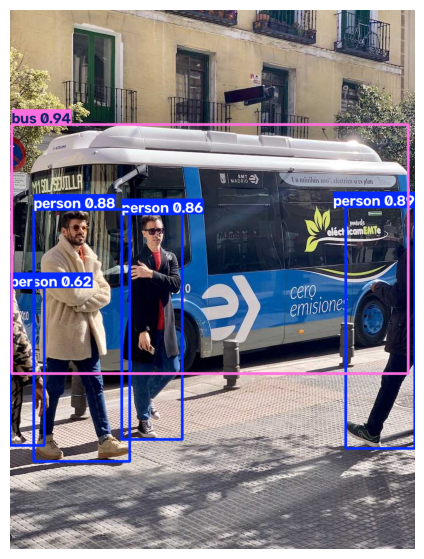

In [7]:
import matplotlib.pyplot as plt

annotated_bgr = r.plot()

plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

좌표, 점수, 클래스 추출

In [8]:
# 탐지 결과에서 정보 추출
xyxy = r.boxes.xyxy.cpu().numpy()
scores = r.boxes.conf.cpu().numpy()
class_ids = r.boxes.cls.cpu().numpy().astype(int)

# 탐지된 객체 정보 출력
for box, score, cid in zip(xyxy, scores, class_ids):
    print(
        r.names[cid],
        round(float(score), 3),
        box.round(1).tolist()
    )

bus 0.94 [3.799999952316284, 229.39999389648438, 796.2000122070312, 728.4000244140625]
person 0.888 [671.0, 394.79998779296875, 809.7999877929688, 878.7000122070312]
person 0.878 [47.400001525878906, 399.6000061035156, 239.3000030517578, 904.2000122070312]
person 0.856 [223.10000610351562, 408.70001220703125, 344.5, 860.4000244140625]
person 0.622 [0.0, 556.0999755859375, 68.9000015258789, 872.4000244140625]


클래스별 탐지 개수 세기

In [9]:
from collections import Counter

counts = Counter(r.names[cid] for cid in class_ids)

print(counts)
print("person:", counts["person"])

Counter({'person': 4, 'bus': 1})
person: 4


관심 클래스만 탐지 결과에 남기기

In [10]:
# person 클래스 ID 찾기
person_id = next(
    k for k, v in model.names.items()
    if v == "person"
)

# 사람만 탐지
people = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    classes=[person_id],
    conf=0.25,
    iou=0.45,
    device=DEVICE,
    verbose=False
)[0]

print("person boxes:", len(people.boxes))

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
person boxes: 4


사람 탐지 결과 시각화(추가 코드)

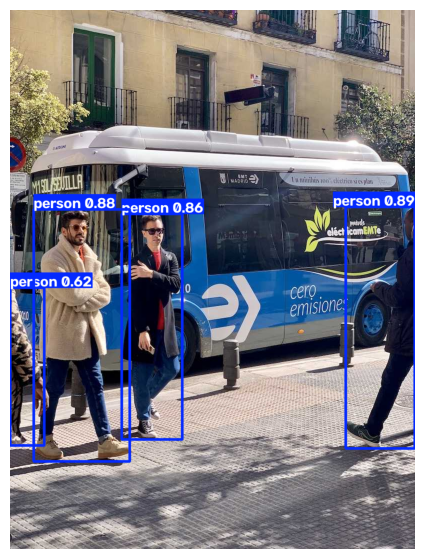

In [11]:
import cv2
import matplotlib.pyplot as plt

people_bgr = people.plot()

plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(people_bgr, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

conf 바꾸어 결과 비교

In [12]:
for c in [0.10, 0.25, 0.50, 0.75]:
  out = model.predict(
      source="https://ultralytics.com/images/bus.jpg",
      conf=c,iou=0.45, classes=None, imgsz=640,
      device=DEVICE,
      verbose=False
  )[0]
  print(c, len(out.boxes))

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
0.1 6
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
0.25 5
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
0.5 5
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
0.75 4


iou 바꾸어 결과 비교

In [13]:
for t in [0.30, 0.50, 0.70]:
  out = model.predict(
      source="https://ultralytics.com/images/bus.jpg",
      conf=0.25,iou=t,imgsz=640,
      device=DEVICE,
      verbose=False
  )[0]
  print(t, len(out.boxes))
  # 후보가 충분히 겹치지 않아서 IoU 값이 달라도 같은 결과 출력

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
0.3 5
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
0.5 5
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
0.7 5


입력 크기 imgsz 비교

In [14]:
for size in [320,640] :
  out = model.predict(
      source="https://ultralytics.com/images/bus.jpg",
      conf=0.25,iou=0.45,imgsz=size,
      device=DEVICE,
      verbose=False
  )[0]

  print(size, len(out.boxes), out.speed)

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
320 5 {'preprocess': 3.7295070001164277, 'inference': 103.8052769999922, 'postprocess': 1.26280799986489}
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
640 5 {'preprocess': 4.844620000085342, 'inference': 273.65998400000535, 'postprocess': 1.5906510000149865}


경계 상자 영역 잘라 보기

In [17]:
from pathlib import Path

OUT = Path("/content/output")
OUT.mkdir(parents=True, exist_ok=True)

if len(r.boxes):
    h, w = r.orig_img.shape[:2]
    x1, y1, x2, y2 = r.boxes.xyxy[0].cpu().numpy()
    x1, x2 = max(0, int(x1)), min(w, int(x2))
    y1, y2 = max(0, int(y1)), min(h, int(y2))
    crop = r.orig_img[y1:y2, x1:x2]
    if crop.size:
        cv2.imwrite(str(OUT /"crop_01.jpg"), crop)

탐지 결과를 표와 파일로 저장

In [18]:
import pandas as pd

rows = [[r.names[c], float(s), *b.tolist()]
        for b, s, c in zip(xyxy, scores, class_ids)]
df = pd.DataFrame(rows, columns=[
    "class", "confidence", "x1", "y1", "x2", "y2"])
df.to_csv(OUT / "detections.csv",
          index=False, encoding="utf-8-sig")
cv2.imwrite(str(OUT / "bus_detected.jpg"), r.plot())

True

## 동영상에서 프레임별 탐지

In [19]:
DATA = Path("/content/data")
OUT.mkdir(parents=True, exist_ok=True)

stream = model.predict(
    source=str(DATA / "sample_video.mp4"),
    stream=True, conf=0.25, iou=0.45,
    imgsz=640, device=DEVICE, verbose=False
)
for frame_no, result in enumerate(stream):
    print(frame_no, len(result.boxes))

0 4
1 4
2 4
3 4
4 4
5 4
6 4
7 4
8 3
9 3
10 3
11 3
12 3
13 3
14 3
15 3


동영상 결과 저장의 핵심

In [21]:
video_path = DATA / "sample_video.mp4"

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise FileNotFoundError(f"동영상 파일을 열 수 없음: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

writer = cv2.VideoWriter(
    str(OUT / "video_detected.mp4"),
    cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
try:
    for result in model.predict(str(video_path),
                                stream=True, device=DEVICE, verbose=False):
        writer.write(result.plot())
finally:
    writer.release()